## Cell 1 — Environment Setup, Reproducibility & Output Directory

In [1]:
import os
import random
import numpy as np
import tensorflow as tf

# --- Reproducibility ---
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- GPU / multi-GPU strategy (matches Notebook 01 / 02) ---
gpus = tf.config.list_physical_devices('GPU')
print("TF version:", tf.__version__)
print("GPUs available:", gpus)

strategy = tf.distribute.MirroredStrategy() if len(gpus) > 1 else tf.distribute.get_strategy()
print("Number of devices in strategy:", strategy.num_replicas_in_sync)

# --- Output directory for this notebook's results ---
OUTPUT_DIR = '/kaggle/working/results'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Output directory ready:", OUTPUT_DIR)

TF version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of devices in strategy: 2
Output directory ready: /kaggle/working/results


I0000 00:00:1784439086.570277      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784439086.573456      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Cell 2 — Explore Attached Inputs (Datasets & Model Notebook)

In [2]:
print("--- datasets ---")
for item in os.listdir('/kaggle/input/datasets'):
    print(item)

print("\n--- notebooks ---")
for item in os.listdir('/kaggle/input/notebooks'):
    print(item)

--- datasets ---
hamzaboulahia
xhlulu

--- notebooks ---
nasrullahbaber


## Cell 3 — Drill Into Dataset & Notebook Folders

In [3]:
print("--- hamzaboulahia ---")
for item in os.listdir('/kaggle/input/datasets/hamzaboulahia'):
    print(item)

print("\n--- xhlulu ---")
for item in os.listdir('/kaggle/input/datasets/xhlulu'):
    print(item)

print("\n--- nasrullahbaber (notebook) ---")
for item in os.listdir('/kaggle/input/notebooks/nasrullahbaber'):
    print(item)

--- hamzaboulahia ---
hardfakevsrealfaces

--- xhlulu ---
140k-real-and-fake-faces

--- nasrullahbaber (notebook) ---
improved-hybrid-deepfake-detector-dfd


## Cell 4 — Inspect Dataset Structure & Model Notebook Output

In [4]:
print("--- hardfakevsrealfaces ---")
for item in os.listdir('/kaggle/input/datasets/hamzaboulahia/hardfakevsrealfaces'):
    print(item)

print("\n--- 140k-real-and-fake-faces ---")
for item in os.listdir('/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces'):
    print(item)

print("\n--- improved-hybrid-deepfake-detector-dfd (notebook output) ---")
for item in os.listdir('/kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd'):
    print(item)

--- hardfakevsrealfaces ---
fake
real
data.csv

--- 140k-real-and-fake-faces ---
valid.csv
real_vs_fake
train.csv
test.csv

--- improved-hybrid-deepfake-detector-dfd (notebook output) ---
checkpoints
results
__results__.html
__notebook__.ipynb
__results___files
logs
__output__.json
custom.css


## Cell 5 — Inspect Dataset Contents, CSV Structure & Model Checkpoint

In [5]:
import pandas as pd

print("--- real_vs_fake (140k) ---")
for item in os.listdir('/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake'):
    print(item)

print("\n--- checkpoints (hybrid model) ---")
for item in os.listdir('/kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/checkpoints'):
    print(item)

print("\n--- hardfakevsrealfaces: fake/real folder samples ---")
fake_files = os.listdir('/kaggle/input/datasets/hamzaboulahia/hardfakevsrealfaces/fake')
real_files = os.listdir('/kaggle/input/datasets/hamzaboulahia/hardfakevsrealfaces/real')
print("fake count:", len(fake_files), "| sample:", fake_files[:3])
print("real count:", len(real_files), "| sample:", real_files[:3])

print("\n--- hardfakevsrealfaces: data.csv preview ---")
df_hard = pd.read_csv('/kaggle/input/datasets/hamzaboulahia/hardfakevsrealfaces/data.csv')
print(df_hard.shape)
print(df_hard.head())

--- real_vs_fake (140k) ---
real-vs-fake

--- checkpoints (hybrid model) ---
best_model.keras
final_model.keras

--- hardfakevsrealfaces: fake/real folder samples ---
fake count: 700 | sample: ['fake_218.jpg', 'fake_94.jpg', 'fake_289.jpg']
real count: 589 | sample: ['real_332.jpg', 'real_541.jpg', 'real_111.jpg']

--- hardfakevsrealfaces: data.csv preview ---
(1289, 2)
  images_id label
0    real_1  real
1   real_10  real
2  real_100  real
3  real_101  real
4  real_102  real


## Cell 6 — Inspect 140k Splits, Hard-Faces Labels & Model Checkpoint Details

In [6]:
print("--- real-vs-fake (140k) ---")
for item in os.listdir('/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'):
    print(item)

print("\n--- 140k CSV shapes & test preview ---")
df_140k_train = pd.read_csv('/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/train.csv')
df_140k_valid = pd.read_csv('/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/valid.csv')
df_140k_test = pd.read_csv('/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/test.csv')
print("train:", df_140k_train.shape, "| valid:", df_140k_valid.shape, "| test:", df_140k_test.shape)
print(df_140k_test.head())

print("\n--- hardfakevsrealfaces label distribution ---")
print(df_hard['label'].value_counts())

print("\n--- checkpoints file sizes ---")
ckpt_dir = '/kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/checkpoints'
for f in os.listdir(ckpt_dir):
    size_mb = os.path.getsize(os.path.join(ckpt_dir, f)) / (1024*1024)
    print(f, f"{size_mb:.1f} MB")

print("\n--- results folder contents ---")
results_dir = '/kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/results'
for item in os.listdir(results_dir):
    print(item)

--- real-vs-fake (140k) ---
valid
test
train

--- 140k CSV shapes & test preview ---
train: (100000, 6) | valid: (20000, 6) | test: (20000, 6)
   Unnamed: 0                                      original_path     id  \
0           0  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  18233   
1           1  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  54317   
2           2  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  40155   
3           3  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  12875   
4           4  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  52543   

   label label_str                 path  
0      1      real  test/real/18233.jpg  
1      1      real  test/real/54317.jpg  
2      1      real  test/real/40155.jpg  
3      1      real  test/real/12875.jpg  
4      1      real  test/real/52543.jpg  

--- hardfakevsrealfaces label distribution ---
label
fake    700
real    589
Name: count, dtype: int64

--- checkpoints file sizes ---
best_model.keras 3

## Cell 7 — Inspect Hybrid Model's Training Manifest & History

In [7]:
import json

results_dir = '/kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/results'

print("--- history.json keys ---")
with open(os.path.join(results_dir, 'history.json')) as f:
    history = json.load(f)
print(list(history.keys()) if isinstance(history, dict) else len(history))

print("\n--- manifest.csv preview ---")
df_manifest = pd.read_csv(os.path.join(results_dir, 'manifest.csv'))
print(df_manifest.shape)
print(df_manifest.columns.tolist())
print(df_manifest.head())

if 'source' in df_manifest.columns:
    print("\nsource counts:")
    print(df_manifest['source'].value_counts())
if 'split' in df_manifest.columns:
    print("\nsplit counts:")
    print(df_manifest['split'].value_counts())

print("\n--- samples folder contents ---")
for item in os.listdir(os.path.join(results_dir, 'samples')):
    print(item)

--- history.json keys ---
['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']

--- manifest.csv preview ---
(30000, 4)
['path', 'label', 'dataset', 'split']
                                                path  label dataset  split
0  /kaggle/input/datasets/sachchitkunichetty/rvf1...      1  rvf10k  train
1  /kaggle/input/datasets/sachchitkunichetty/rvf1...      0  rvf10k  train
2  /kaggle/input/datasets/sachchitkunichetty/rvf1...      0  rvf10k  train
3  /kaggle/input/datasets/sachchitkunichetty/rvf1...      0  rvf10k  train
4  /kaggle/input/datasets/sachchitkunichetty/rvf1...      1  rvf10k  train

split counts:
split
train    21000
val       6000
test      3000
Name: count, dtype: int64

--- samples folder contents ---
rvf10k_real_3.jpg
samples_manifest.csv
rvf10k_real_1.jpg
sgan3_fake_1.png
rvf10k_real_0.jpg
sgan3_fake_3.png
rvf10k_fake_2.jpg
rvf10k_fake_0.jpg
rvf10k_fake_3.jpg
sgan3_real_1.png
sgan3_real_2.png
rvf10k_fake_1.jpg
sample_grid.pdf
sgan3_fake_2.png
sample

## Cell 8 — Compare Best vs Final Checkpoint via Training History

In [8]:
n_epochs = len(history['loss'])
best_epoch = int(np.argmin(history['val_loss']))

print(f"Total epochs trained: {n_epochs}")
print(f"Best epoch (lowest val_loss): {best_epoch + 1} | val_loss={history['val_loss'][best_epoch]:.4f} | val_accuracy={history['val_accuracy'][best_epoch]:.4f}")
print(f"Final epoch: {n_epochs} | val_loss={history['val_loss'][-1]:.4f} | val_accuracy={history['val_accuracy'][-1]:.4f}")

print("\n--- dataset composition (manifest) ---")
print(df_manifest['dataset'].value_counts())

Total epochs trained: 34
Best epoch (lowest val_loss): 26 | val_loss=0.3316 | val_accuracy=0.9523
Final epoch: 34 | val_loss=0.3319 | val_accuracy=0.9528

--- dataset composition (manifest) ---
dataset
sgan3     20000
rvf10k    10000
Name: count, dtype: int64


## Cell 9 — Load Hybrid Model & Build Balanced 140k Test Sample (2000/2000, seed=42)

In [9]:
MODEL_PATH = '/kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/checkpoints/best_model.keras'
model = tf.keras.models.load_model(MODEL_PATH)
print("Model loaded:", MODEL_PATH)
print("Total params:", model.count_params())

# Balanced stratified sample from 140k test set: 2000 real + 2000 fake, seed=42
IMG_DIR_140K = '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'

real_df = df_140k_test[df_140k_test['label_str'] == 'real'].sample(n=2000, random_state=SEED)
fake_df = df_140k_test[df_140k_test['label_str'] == 'fake'].sample(n=2000, random_state=SEED)

sample_140k = pd.concat([real_df, fake_df]).sample(frac=1, random_state=SEED).reset_index(drop=True)
sample_140k['full_path'] = sample_140k['path'].apply(lambda p: os.path.join(IMG_DIR_140K, p))

print(sample_140k.shape)
print(sample_140k['label_str'].value_counts())
print(sample_140k[['full_path', 'label', 'label_str']].head())
print("\nSample path exists:", os.path.exists(sample_140k['full_path'].iloc[0]))

Model loaded: /kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/checkpoints/best_model.keras
Total params: 22651457
(4000, 7)
label_str
real    2000
fake    2000
Name: count, dtype: int64
                                           full_path  label label_str
0  /kaggle/input/datasets/xhlulu/140k-real-and-fa...      1      real
1  /kaggle/input/datasets/xhlulu/140k-real-and-fa...      0      fake
2  /kaggle/input/datasets/xhlulu/140k-real-and-fa...      1      real
3  /kaggle/input/datasets/xhlulu/140k-real-and-fa...      0      fake
4  /kaggle/input/datasets/xhlulu/140k-real-and-fa...      0      fake

Sample path exists: True


## Cell 10 — Build tf.data Pipeline for 140k Sample

In [10]:
IMG_SIZE = 256
BATCH_SIZE = 32

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.keras.applications.vgg19.preprocess_input(img)
    return img, label

paths = sample_140k['full_path'].values
labels = sample_140k['label'].values

test_ds_140k = tf.data.Dataset.from_tensor_slices((paths, labels))
test_ds_140k = test_ds_140k.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test_ds_140k = test_ds_140k.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# sanity check
for imgs, lbls in test_ds_140k.take(1):
    print("Batch shape:", imgs.shape, "Labels shape:", lbls.shape)
    print("Pixel range:", float(tf.reduce_min(imgs)), "to", float(tf.reduce_max(imgs)))

Batch shape: (32, 256, 256, 3) Labels shape: (32,)
Pixel range: -123.68000030517578 to 151.06100463867188


In [11]:
IMG_SIZE = 256
BATCH_SIZE = 32

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.keras.applications.vgg19.preprocess_input(img)
    return img, label

paths = sample_140k['full_path'].values
labels = sample_140k['label'].values

test_ds_140k = tf.data.Dataset.from_tensor_slices((paths, labels))
test_ds_140k = test_ds_140k.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test_ds_140k = test_ds_140k.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report)

y_true_140k = labels
y_pred_probs_140k = model.predict(test_ds_140k, verbose=1).flatten()
y_pred_140k = (y_pred_probs_140k >= 0.5).astype(int)

acc = accuracy_score(y_true_140k, y_pred_140k)
prec = precision_score(y_true_140k, y_pred_140k)
rec = recall_score(y_true_140k, y_pred_140k)
f1 = f1_score(y_true_140k, y_pred_140k)
auc = roc_auc_score(y_true_140k, y_pred_probs_140k)
cm = confusion_matrix(y_true_140k, y_pred_140k)
report = classification_report(y_true_140k, y_pred_140k, target_names=["fake", "real"])

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(report)

exp2_summary = {
    "Experiment": "Exp2_140k_SameFamily",
    "Dataset": "140k Real and Fake Faces (test split, n=4000 balanced)",
    "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1, "ROC_AUC": auc
}
pd.DataFrame([exp2_summary])

125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 176ms/step
Accuracy:  0.9617
Precision: 0.9588
Recall:    0.9650
F1-score:  0.9619
ROC-AUC:   0.9934

Confusion Matrix:
[[1917   83]
 [  70 1930]]

Classification Report:
              precision    recall  f1-score   support

        fake       0.96      0.96      0.96      2000
        real       0.96      0.96      0.96      2000

    accuracy                           0.96      4000
   macro avg       0.96      0.96      0.96      4000
weighted avg       0.96      0.96      0.96      4000



,Experiment,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC
0,Exp2_140k_SameFamily,"140k Real and Fake Faces (test split, n=4000 b...",0.96175,0.958768,0.965,0.961874,0.99341


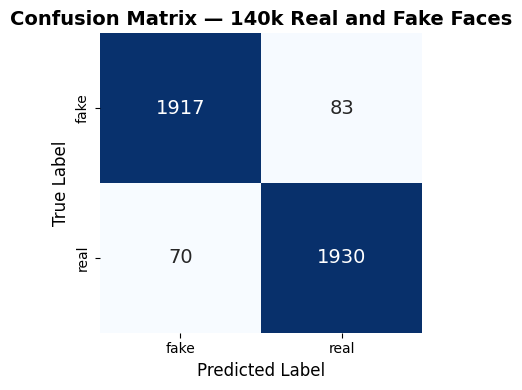

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_confusion_matrix(cm, title, save_name):
    plt.figure(figsize=(4, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['fake', 'real'], yticklabels=['fake', 'real'],
                cbar=False, annot_kws={"size": 14})
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{save_name}.png'), dpi=300)
    plt.savefig(os.path.join(OUTPUT_DIR, f'{save_name}.pdf'))
    plt.show()

plot_confusion_matrix(cm, "Confusion Matrix — 140k Real and Fake Faces", "cm_140k")

## Cell 11 — Full Evaluation on Hard-Faces (Balanced 589/589)

In [13]:
# Balance the Hard-Faces set (700 fake / 589 real -> 589/589)
IMG_DIR_HARD = '/kaggle/input/datasets/hamzaboulahia/hardfakevsrealfaces'

real_hard = df_hard[df_hard['label'] == 'real'].sample(n=589, random_state=SEED)
fake_hard = df_hard[df_hard['label'] == 'fake'].sample(n=589, random_state=SEED)
sample_hard = pd.concat([real_hard, fake_hard]).sample(frac=1, random_state=SEED).reset_index(drop=True)

sample_hard['full_path'] = sample_hard.apply(
    lambda r: os.path.join(IMG_DIR_HARD, r['label'], r['images_id'] + '.jpg'), axis=1
)
sample_hard['label_bin'] = (sample_hard['label'] == 'real').astype(int)

print("Path exists check:", sample_hard['full_path'].apply(os.path.exists).mean())

paths_hard = sample_hard['full_path'].values
labels_hard = sample_hard['label_bin'].values

test_ds_hard = tf.data.Dataset.from_tensor_slices((paths_hard, labels_hard))
test_ds_hard = test_ds_hard.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test_ds_hard = test_ds_hard.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

y_true_hard = labels_hard
y_pred_probs_hard = model.predict(test_ds_hard, verbose=1).flatten()
y_pred_hard = (y_pred_probs_hard >= 0.5).astype(int)

acc_h = accuracy_score(y_true_hard, y_pred_hard)
prec_h = precision_score(y_true_hard, y_pred_hard)
rec_h = recall_score(y_true_hard, y_pred_hard)
f1_h = f1_score(y_true_hard, y_pred_hard)
auc_h = roc_auc_score(y_true_hard, y_pred_probs_hard)
cm_h = confusion_matrix(y_true_hard, y_pred_hard)
report_h = classification_report(y_true_hard, y_pred_hard, target_names=["fake", "real"])

print(f"Accuracy:  {acc_h:.4f}")
print(f"Precision: {prec_h:.4f}")
print(f"Recall:    {rec_h:.4f}")
print(f"F1-score:  {f1_h:.4f}")
print(f"ROC-AUC:   {auc_h:.4f}")
print("\nConfusion Matrix:")
print(cm_h)
print("\nClassification Report:")
print(report_h)

exp4_summary = {
    "Experiment": "Exp4_HardFakeVsReal_CrossDomain",
    "Dataset": "Hard Fake vs Real Faces (n=1178 balanced)",
    "Accuracy": acc_h, "Precision": prec_h, "Recall": rec_h, "F1": f1_h, "ROC_AUC": auc_h
}
pd.DataFrame([exp4_summary])

Path exists check: 1.0
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 279ms/step
Accuracy:  0.9346
Precision: 0.8879
Recall:    0.9949
F1-score:  0.9384
ROC-AUC:   0.9906

Confusion Matrix:
[[515  74]
 [  3 586]]

Classification Report:
              precision    recall  f1-score   support

        fake       0.99      0.87      0.93       589
        real       0.89      0.99      0.94       589

    accuracy                           0.93      1178
   macro avg       0.94      0.93      0.93      1178
weighted avg       0.94      0.93      0.93      1178



,Experiment,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC
0,Exp4_HardFakeVsReal_CrossDomain,Hard Fake vs Real Faces (n=1178 balanced),0.934635,0.887879,0.994907,0.938351,0.990586


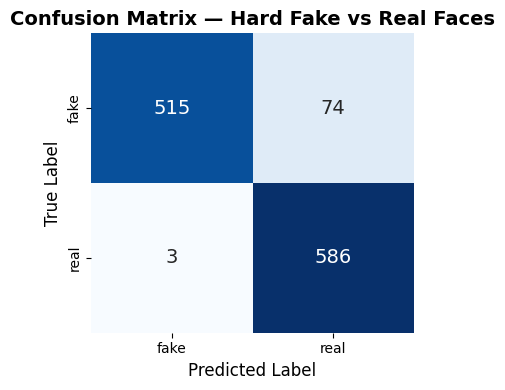

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
def plot_confusion_matrix(cm, title, save_name):
    plt.figure(figsize=(4, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['fake', 'real'], yticklabels=['fake', 'real'],
                cbar=False, annot_kws={"size": 14})
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{save_name}.png'), dpi=300)
    plt.savefig(os.path.join(OUTPUT_DIR, f'{save_name}.pdf'))
    plt.show()

plot_confusion_matrix(cm_h, "Confusion Matrix — Hard Fake vs Real Faces", "cm_hard")

## Cell 12 — Combined Results Table & Export (CSV + Excel)

In [15]:
final_results = pd.DataFrame([exp2_summary, exp4_summary])
final_results = final_results[["Experiment", "Dataset", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]]

csv_path = os.path.join(OUTPUT_DIR, "cross_dataset_results.csv")
excel_path = os.path.join(OUTPUT_DIR, "cross_dataset_results.xlsx")

final_results.to_csv(csv_path, index=False)
final_results.to_excel(excel_path, index=False)

print("Saved to:", csv_path)
print("Saved to:", excel_path)
final_results

Saved to: /kaggle/working/results/cross_dataset_results.csv
Saved to: /kaggle/working/results/cross_dataset_results.xlsx


,Experiment,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC
0,Exp2_140k_SameFamily,"140k Real and Fake Faces (test split, n=4000 b...",0.961750,0.958768,0.965000,0.961874,0.993410
1,Exp4_HardFakeVsReal_CrossDomain,Hard Fake vs Real Faces (n=1178 balanced),0.934635,0.887879,0.994907,0.938351,0.990586
